Made by Claude. Ring scale fixed by me

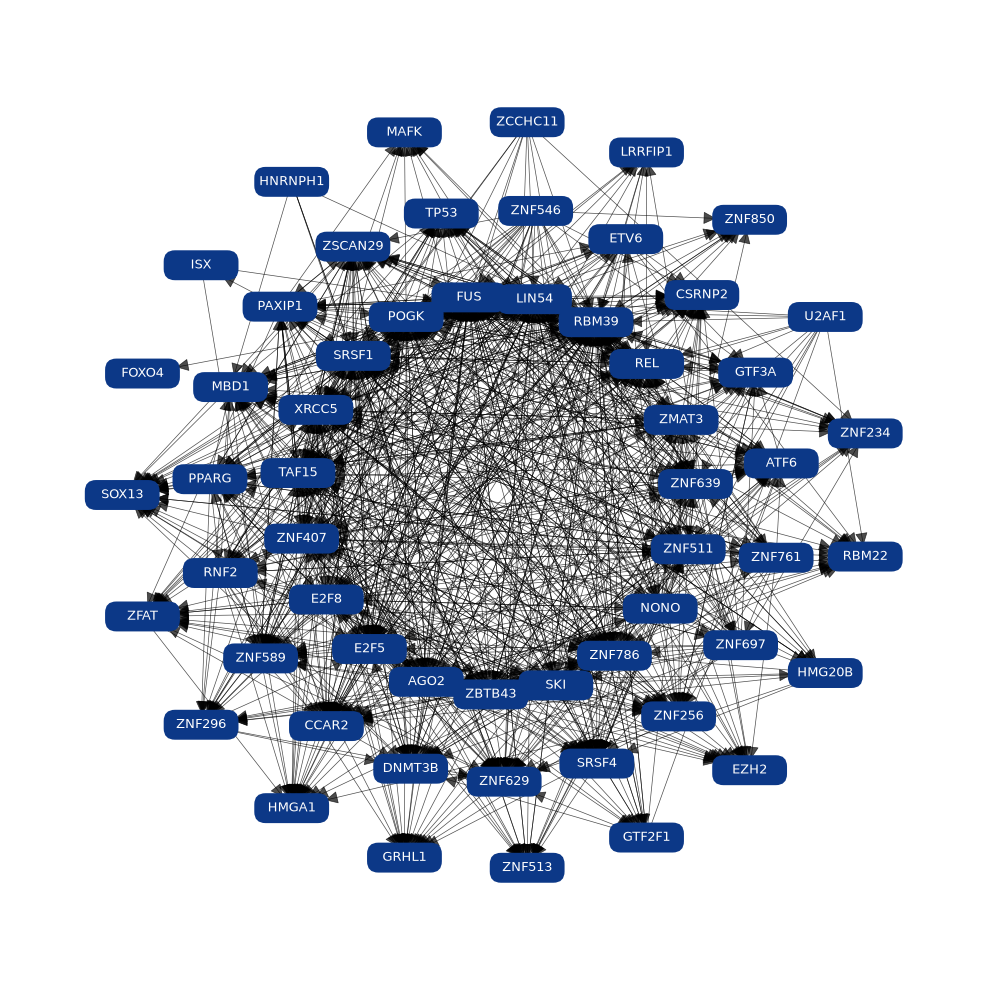

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

#G = nx.read_graphml("../results/networks/2026-08-06_grn-combined-TF-nodes-only.graphml")
G = nx.read_graphml("../results/networks/2026-08-11_grn-combined-TF-nodes-only.graphml")

degrees = dict(G.degree())
sorted_nodes = sorted(degrees, key=degrees.get, reverse=True)

n = len(sorted_nodes)
shells = [
    sorted_nodes[:n//3],
    sorted_nodes[n//3:2*n//3],
    sorted_nodes[2*n//3:]
]

# Ring layout
pos = nx.shell_layout(G, nlist=shells)
inner_scale = 1.6    # innermost ring
middle_scale = 1.15  # middle ring scales up about half as much
for node in shells[0]:  # innermost ring
    x, y = pos[node]
    pos[node] = (x * inner_scale, y * inner_scale)
for node in shells[1]:  # middle ring
    x, y = pos[node]
    pos[node] = (x * middle_scale, y * middle_scale)


box_width, box_height = 0.18, 0.06

def rect_border_point(cx, cy, tx, ty, w, h):
    """Point where the line from (cx,cy) to (tx,ty) crosses the rectangle
    of width w, height h centered at (cx,cy)."""
    dx, dy = tx - cx, ty - cy
    if dx == 0 and dy == 0:
        return cx, cy
    half_w, half_h = w / 2, h / 2
    # scale factor to hit vertical edges vs horizontal edges
    scale_x = half_w / abs(dx) if dx != 0 else float('inf')
    scale_y = half_h / abs(dy) if dy != 0 else float('inf')
    scale = min(scale_x, scale_y)
    return cx + dx * scale, cy + dy * scale

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('white')

# Draw rectangles
for node, (x, y) in pos.items():
    box = FancyBboxPatch(
        (x - box_width/2, y - box_height/2), box_width, box_height,
        boxstyle="round,pad=0.01,rounding_size=0.03",
        linewidth=0, edgecolor='none', facecolor='#0c3887', zorder=3 # 1f77b4
    )
    ax.add_patch(box)

# Draw each edge manually, clipped to rectangle borders on both ends
for u, v in G.edges():
    x1, y1 = pos[u]
    x2, y2 = pos[v]

    start_x, start_y = rect_border_point(x1, y1, x2, y2, box_width, box_height)
    end_x, end_y = rect_border_point(x2, y2, x1, y1, box_width, box_height)

    arrow = FancyArrowPatch(
        (start_x, start_y), (end_x, end_y),
        arrowstyle='-|>', mutation_scale=20, # controls size of arrowheads
        facecolor='black', edgecolor='black', alpha=0.7, linewidth=.5, # edgecolor='#cccccc', linewidth was 1.2
        zorder=2, shrinkA=0, shrinkB=0
    )
    ax.add_patch(arrow)

# Labels in black, normal weight
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_color='white', font_weight='normal')

ax.set_aspect('equal')
ax.axis('off')
ax.set_xlim(min(x for x, y in pos.values()) - 0.3, max(x for x, y in pos.values()) + 0.3)
ax.set_ylim(min(y for x, y in pos.values()) - 0.3, max(y for x, y in pos.values()) + 0.3)

plt.tight_layout()
plt.savefig("../results/networks/2026-08-09_graph-2.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

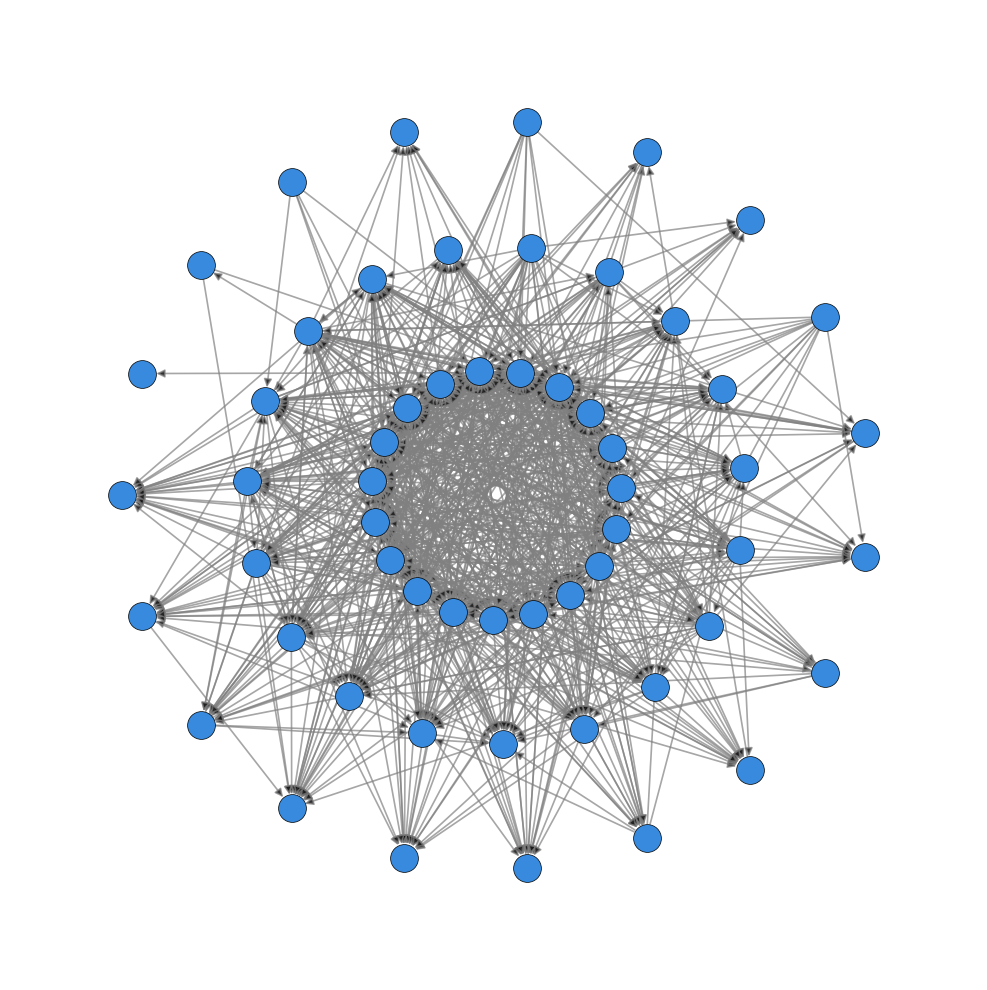

In [7]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

degrees = dict(G.degree())
sorted_nodes = sorted(degrees, key=degrees.get, reverse=True)
n = len(sorted_nodes)
shells = [sorted_nodes[:n//3], sorted_nodes[n//3:2*n//3], sorted_nodes[2*n//3:]]

pos = nx.shell_layout(G, nlist=shells)
#inner_scale, middle_scale, outer_scale = 1.6, 1.15, 1
inner_scale, middle_scale, outer_scale = 1, 1, 1
for node in shells[0]:
    x, y = pos[node]; pos[node] = (x * inner_scale, y * inner_scale)
for node in shells[1]:
    x, y = pos[node]; pos[node] = (x * middle_scale, y * middle_scale)
for node in shells[2]:
    x, y = pos[node]; pos[node] = (x * outer_scale, y * outer_scale)

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_facecolor('white')

node_size = 400
node_radius_pts = (node_size ** 0.5) / 2  # approx marker radius in points

# draw edges first, so nodes sit on top
for u, v in G.edges():
    x1, y1 = pos[u]
    x2, y2 = pos[v]
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='-|>', mutation_scale=12,
        facecolor='black',   # arrowhead fill
        edgecolor='grey',    # line/shaft color
        alpha=0.7, linewidth=1.2,
        shrinkA=node_radius_pts, shrinkB=node_radius_pts,  # stop at circle edge
        zorder=2,
    )
    ax.add_patch(arrow)

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color='#378ADD',
    edgecolors='black',
    linewidths=0.5,
    node_size=node_size,
)

ax.set_aspect('equal')
ax.axis('off')
ax.set_xlim(min(x for x, y in pos.values()) - 0.3, max(x for x, y in pos.values()) + 0.3)
ax.set_ylim(min(y for x, y in pos.values()) - 0.3, max(y for x, y in pos.values()) + 0.3)
plt.tight_layout()
plt.savefig("../results/networks/2026-08-09_graph-3.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()